# Integrating Tools into an Agent: Practice Exercise

In this exercise, you'll integrate the **Wikipedia search tool** into a LangChain agent. This reinforces the pattern of adding external tools to give agents real-world capabilities.

**What you'll implement:**
- Configure and instantiate a Wikipedia search tool
- Create an agent with the tool integrated

**Estimated time:** 10 minutes

## Setup

Run this cell to import all required libraries and configure the environment.

## Context

You are building a research assistant that can look up factual information from Wikipedia. The agent should be able to answer questions about historical events, scientific concepts, notable people, and other encyclopedic topics.

**Your task:**
- Create a Wikipedia search tool using `WikipediaQueryRun` and `WikipediaAPIWrapper`

**Tool configuration:**
- The `WikipediaAPIWrapper` accepts `top_k_results` (number of results) and `doc_content_chars_max` (max characters per result)
- Use `top_k_results=3` and `doc_content_chars_max=2000` for balanced results

**Expected behavior:**
- The tool should be able to query Wikipedia and return relevant information
- We'll provide the agent setup for you - you just need to create the tool

# install modules

In [5]:
!pip install wikipedia

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for wikipedia: filename=wikipedia-1.4.0-py3-none-any.whl size=11785 sha256=8edec96c058af3cfa5715bf3efa5426317dd5a76923ad39ac6303ebbc66bd30c
  Stored in directory: c:\users\ayman\appdata\local\pip\cache\wheels\63\47\7c\a9688349aa74d228ce0a9023229c6c0ac52ca2a40fe87679b8
Successfully built wikipedia



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
!pip install -U wikipedia langchain-community

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.4 MB 2.8 MB/s eta 0:00:01
   ----------------------------------- ---- 2.1/2.4 MB 6.2 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 5.6 MB/s  0:00:00
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 1.0/1.0 MB 12.6 MB/s  0:00:00

  Attempting uninstall: pydantic-settings

    Found existing installation: pydantic-settings 2.6.1

    Uninstalling pydantic-settings-2.6.1:

      Successfully uninstalled pydantic-settings-2.6.1

   -------- ------------------------------- 1/5 [pydantic-settings]
   -------- ------------------------------- 1/5 [pydantic-settings]
  Attempting uninstall: langchain-text-splitters
   -------- ------------------------------- 1/5 [pydantic-settings]
    Found existing installation: langcha


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# import modules

In [6]:
# Setup - run this cell first
import os
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain_groq import ChatGroq
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

# Load environment variables
load_dotenv()

if not os.getenv("GROQ_API_KEY"):
    raise ValueError("GROQ_API_KEY not found in environment variables")

print("Setup complete!")

Setup complete!


# check if wiki accept messages from my machine 

In [31]:
import wikipedia
#descriptive name of the user : you can change it
wikipedia.wikipedia.USER_AGENT = "razan-notebook/1.0"


In [22]:
import requests
r = requests.get(
    "https://en.wikipedia.org/w/api.php",
    params={"action": "query", "list": "search", "srsearch": "Python", "format": "json"},
    headers={"User-Agent": "my-notebook/1.0"},
    timeout=10,
)
print(r.status_code)
print(r.text[:300])

200
{"batchcomplete":"","continue":{"sroffset":10,"continue":"-||"},"query":{"searchinfo":{"totalhits":13550},"search":[{"ns":0,"title":"Python (programming language)","pageid":23862,"size":144559,"wordcount":11603,"snippet":"<span class=\"searchmatch\">Python</span> is a high-level, general-purpose pro


## Your Task: Create the Wikipedia Search Tool

Implement a function that creates and returns a configured Wikipedia search tool.

In [34]:
def create_wikipedia_tool():
    #docstring: tool description
    """
    Create a Wikipedia search tool for querying encyclopedic information.
    
    The tool should be configured with:
    - top_k_results: 3 (return top 3 Wikipedia articles)
    - doc_content_chars_max: 2000 (limit content length per result)
    
    Returns:
        WikipediaQueryRun: A configured Wikipedia search tool instance
    
    Hint: WikipediaQueryRun takes an api_wrapper parameter 
    """
    #the wrapper is only the low-level client that talks directly to Wikipedia
    # TODO: Create and return the Wikipedia search tool
    api_wrapper = WikipediaAPIWrapper(
        top_k_results=3,
        doc_content_chars_max=2000)
    return WikipediaQueryRun(api_wrapper=api_wrapper,     description="Look up factual information on Wikipedia. Use this for any question about "
                    "history, people, science, or events. Input should be a search query.",
                    name="wikipedia")


## Agent Setup

Below is the agent setup code - you don't need to modify this. It will use your Wikipedia tool.

In [35]:
# Agent setup - run this after creating your tool

def create_research_agent(wiki_tool):
    """
    Create a LangChain agent with Wikipedia search capability.
    
    Args:
        wiki_tool: A WikipediaQueryRun tool instance
    
    Returns:
        Agent: A configured LangChain agent
    """
    model = ChatGroq(model="openai/gpt-oss-20b", temperature=0.1)
    agent = create_agent(model=model, tools=[wiki_tool])
    return agent

# Note 
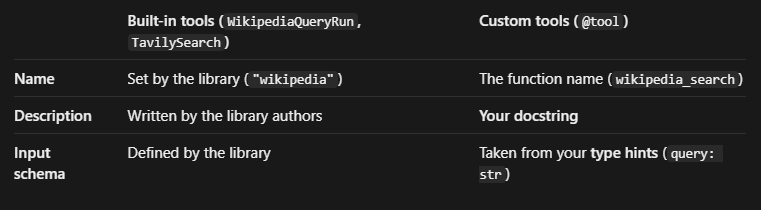

## Test Your Implementation

Run the cells below to test your Wikipedia tool with the agent.

In [36]:
# Create the Wikipedia tool
wiki_tool = create_wikipedia_tool()
print(f"Tool created: {wiki_tool.name}")
print(f"Description: {wiki_tool.description[:100]}...")

Tool created: wikipedia
Description: Look up factual information on Wikipedia. Use this for any question about history, people, science, ...


In [26]:
# Create the agent
research_agent = create_research_agent(wiki_tool)
print("Research agent created successfully!")

Research agent created successfully!


In [ ]:
# Test with a factual query
query = "Who invented the telephone and when?"
#print the query
print(f"Query: {query}\n")
print("=" * 60)

# Invoke the agent and capture the result
result = research_agent.invoke({
    "messages": [{"role": "user", "content": query}]
})

# Extract and display tool calls
print("\n🔧 TOOL CALLS MADE:")
print("-" * 60)
for msg in result['messages']:
    #if the message has used the tool because msh has 4 attributes
    if hasattr(msg, 'tool_calls') and msg.tool_calls:
        for tool_call in msg.tool_calls:
            print(f"Tool: {tool_call['name']}")
            #the chosen query the model chose
            print(f"Query: {tool_call['args']['query']}")
            print()

# Display tool responses
print("📚 TOOL RESPONSES:")
print("-" * 60)
for msg in result['messages']:
    #tool name 
    if hasattr(msg, 'name') and msg.name == 'wikipedia':
        # Truncate long responses for display
        content_preview = msg.content[:500] + "..." if len(msg.content) > 500 else msg.content
        print(content_preview)
        print()

# Display final answer
print("💬 FINAL ANSWER:")
print("-" * 60)
print(f"{result['messages'][-1].content}")
print("=" * 60)

Query: Who invented the telephone and when?


🔧 TOOL CALLS MADE:
------------------------------------------------------------
📚 TOOL RESPONSES:
------------------------------------------------------------
💬 FINAL ANSWER:
------------------------------------------------------------
Alexander Graham Bell is credited with inventing the first practical telephone. He was granted the U.S. patent for the telephone on **March 7, 1876**. (Bell’s invention was soon followed by competing claims, notably by Elisha Gray, but Bell’s design and patent established him as the inventor.)


In [33]:
# Test with a factual query
query = "Use Wikipedia to answer: Who invented the telephone and when?"
print(f"Query: {query}\n")
print("=" * 60)

# Invoke the agent and capture the result
result = research_agent.invoke({
    "messages": [{"role": "user", "content": query}]
})

# Extract and display tool calls
print("\n🔧 TOOL CALLS MADE:")
print("-" * 60)
for msg in result['messages']:
    if hasattr(msg, 'tool_calls') and msg.tool_calls:
        for tool_call in msg.tool_calls:
            print(f"Tool: {tool_call['name']}")
            print(f"Query: {tool_call['args']['query']}")
            print()

# Display tool responses
print("📚 TOOL RESPONSES:")
print("-" * 60)
for msg in result['messages']:
    if hasattr(msg, 'name') and msg.name == 'wikipedia':
        # Truncate long responses for display
        content_preview = msg.content[:500] + "..." if len(msg.content) > 500 else msg.content
        print(content_preview)
        print()

# Display final answer
print("💬 FINAL ANSWER:")
print("-" * 60)
print(f"{result['messages'][-1].content}")
print("=" * 60)

Query: Use Wikipedia to answer: Who invented the telephone and when?


🔧 TOOL CALLS MADE:
------------------------------------------------------------
Tool: wikipedia
Query: telephone invention Alexander Graham Bell 1876

📚 TOOL RESPONSES:
------------------------------------------------------------
Page: Invention of the telephone
Summary: The invention of the telephone was the culmination of work done by many different people, and led to an array of lawsuits relating to the conflicting patent claims made by several individuals and numerous companies. Notable people included in this process were Antonio Meucci, Philipp Reis, Elisha Gray and Alexander Graham Bell.

Page: Alexander Graham Bell
Summary: Alexander Graham Bell ( ; born Alexander Bell; March 3, 1847 – August 2, 1922) was a  Scot...

💬 FINAL ANSWER:
------------------------------------------------------------
**Answer**

The telephone was first patented by **Alexander Graham Bell**.  
He received the United States patent for

# try to instruct the model to use the tool for any search

In [37]:
def create_research_agent(wiki_tool):
    """
    Create a LangChain agent with Wikipedia search capability.
    
    Args:
        wiki_tool: A WikipediaQueryRun tool instance
    
    Returns:
        Agent: A configured LangChain agent
    """
    model = ChatGroq(model="openai/gpt-oss-20b", temperature=0.1)
    agent = create_agent(model=model, tools=[wiki_tool], system_prompt="Always use the Wikipedia tool to look up facts before answering.",
)
    return agent

In [38]:
# Create the agent
research_agent = create_research_agent(wiki_tool)
print("Research agent created successfully!")

Research agent created successfully!


In [42]:
# Test with a factual query
query = "Who invented the telephone and when?"
#print the query
print(f"Query: {query}\n")
print("=" * 60)

# Invoke the agent and capture the result
result = research_agent.invoke({
    "messages": [{"role": "user", "content": query}]
})
# Display the model's (AI) messages
print("🤖 AI MESSAGES:")
print("-" * 60)
ai_count = 0
for msg in result['messages']:
    if msg.type == "ai":
        ai_count += 1
        print(f"AI message #{ai_count}:")
        if msg.tool_calls:
            print(f"  (decided to call tool: {msg.tool_calls[0]['name']})")
            break
        
# Extract and display tool calls
print("\n🔧 TOOL CALLS MADE:")
print("-" * 60)
for msg in result['messages']:
    #if the message has used the tool because msh has 4 attributes
    if hasattr(msg, 'tool_calls') and msg.tool_calls:
        for tool_call in msg.tool_calls:
            print(f"Tool: {tool_call['name']}")
            #the chosen query the model chose
            print(f"Query: {tool_call['args']['query']}")
            print()

# Display tool responses
print("📚 TOOL RESPONSES:")
print("-" * 60)
for msg in result['messages']:
    #tool name 
    if hasattr(msg, 'name') and msg.name == 'wikipedia':
        # Truncate long responses for display
        content_preview = msg.content[:500] + "..." if len(msg.content) > 500 else msg.content
        print(content_preview)
        print()

# Display final answer
print("💬 FINAL ANSWER:")
print("-" * 60)
print(f"{result['messages'][-1].content}")
print("=" * 60)

Query: Who invented the telephone and when?

🤖 AI MESSAGES:
------------------------------------------------------------
AI message #1:
  (decided to call tool: wikipedia)

🔧 TOOL CALLS MADE:
------------------------------------------------------------
Tool: wikipedia
Query: inventor of the telephone

📚 TOOL RESPONSES:
------------------------------------------------------------
Page: Invention of the telephone
Summary: The invention of the telephone was the culmination of work done by many different people, and led to an array of lawsuits relating to the conflicting patent claims made by several individuals and numerous companies. Notable people included in this process were Antonio Meucci, Philipp Reis, Elisha Gray and Alexander Graham Bell.

Page: History of the telephone
Summary: This history of the telephone chronicles the development of the electrical telephone, a...

💬 FINAL ANSWER:
------------------------------------------------------------
The telephone is generally credited 